# ***TRABAJO PRACTICO DE INVESTIGACION: CLASIFICACION DE VINOS***

## *PRIMERA PARTE: ANALISIS DE BASE DE DATOS*

Para este Trabajo Practico, nos enfocaremos en tratar de buscar correlacion entre datos fisico-quimicos de una buena cantidad de vinos, con su "calidad". 
Estos vinos estan evaluados por mas de una persona, y se puntuan en la escala del 1 al 10.
Dichos datos son datos reales, extraidos de un estudio realizado por Paulo Cortez, Antonio Cerdeira, Fernando Almeida, Telmo Matos, y Jose Reis (de la Universidad de Minho y la Comision de Viticultura de la Region de Vinho Verde (en Portugal), facilmente comprobable en la web.


Lo primero que haremos es analizar nuestra base de datos para entender su estructura y contenido.

In [8]:
import pandas as pd 
import matplotlib.pyplot as plt
import numpy as np

df=pd.read_csv('vinos.csv')
df.describe()

,FixedAcidity,VolatileAcidity,CitricAcid,ResidualSugar,Chlorides,FreeSulfurDioxide,TotalSulfurDioxide,Density,pH,Sulphates,Alcohol,Quality[DV]
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525473,115.744728,0.994697,3.218501,0.531268,10.491801,5.818378
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749313,56.521751,0.002999,0.160787,0.148806,1.192712,0.873255
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


In [9]:
df['Quality[DV]'].median()                              # da 6.0

np.float64(6.0)

***A) Para entender todo mejor, pasamos todo a español. Las 11 primeras columnas son variables numericas continuas (mediciones fisicoquimicas del vino):***

- *AcidezFija: acidez fija del vino, acidos no volatiles (g/L). Numerica continua.*
- *AcidezVolatil: acidez volatil, principalmente acido acetico (g/L). Numerica continua.*
- *AcidoCitrico: cantidad de acido citrico (g/L). Numerica continua.*
- *AzucarResidual: azucar que queda despues de la fermentacion (g/L). Numerica continua.*
- *Cloruros: cantidad de sal (g/L). Numerica continua.*
- *DioxidoAzufreLibre: dioxido de azufre libre (mg/L). Numerica continua.*
- *DioxidoAzufreTotal: dioxido de azufre total, libre mas combinado (mg/L). Numerica continua.*
- *Densidad: densidad del vino (g/cm³). Numerica continua.*
- *pH: nivel de acidez en escala de pH, sin unidad. Numerica continua.*
- *Sulfatos: sulfatos, aditivo del vino (g/L). Numerica continua.*
- *Alcohol: contenido de alcohol (% vol.). Numerica continua.*
- *Color: tipo de vino. Categorica nominal binaria, codificada como 1 = tinto y 0 = blanco. Se usa como entrada.*
- *Calidad: puntaje de calidad dado por catadores, de 3 a 9. Categorica ordinal, que converti a binaria (1 = buena calidad, 6 o mas; 0 = mala calidad, 5 o menos). Es la salida del modelo.*

***C) La base es adecuada para una red neuronal de clasificacion binaria: tiene 6.497 vinos reales, sin valores faltantes, con 12 variables de entrada numericas y una salida binaria (63% de vinos buenos y 37% de malos). El modelo intentara predecir si un vino es de buena calidad (1) o de mala calidad (0) a partir de sus caracteristicas fisicoquimicas y su color. Para esto definiremos, en base a la mediana obtenida, que una calificacion arriba de 6 es "buena", osea '1', y una de 5 o menos es "mala", es decir '0', hablando en terminos binarios.***

***El objetivo es aprender la relacion entre esas caracteristicas y la calidad, para clasificar correctamente vinos nuevos sin la necesidad de convocar una nueva cata de expertos, que implicaria tal vez mucho costo.***

In [10]:
df = df.rename(columns={
    'FixedAcidity':       'AcidezFija',
    'VolatileAcidity':    'AcidezVolatil',
    'CitricAcid':         'AcidoCitrico',
    'ResidualSugar':      'AzucarResidual',
    'Chlorides':          'Cloruros',
    'FreeSulfurDioxide':  'DioxidoAzufreLibre',
    'TotalSulfurDioxide': 'DioxidoAzufreTotal',
    'Density':            'Densidad',
    'pH':                 'pH',
    'Sulphates':          'Sulfatos',
    'Alcohol':            'Alcohol',
    'Quality[DV]':        'Calidad',
    'Color[DV]':          'Color',
})

df['y'] = (df['Calidad'] >= 6).astype(int)
df['Color'] = df['Color'].map({'Red': 1, 'White': 0})
df['Color'].value_counts()   # para verificar: 4898 con 0 y 1599 con 1

Color
0    4898
1    1599
Name: count, dtype: int64

Lo siguiente a hacer es buscar correlacion entre mis entradas y mi salida. Podemos verlo facilmente con este codigo 

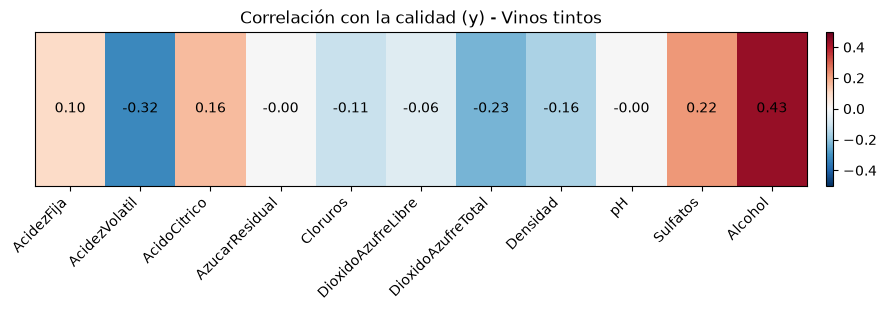

In [11]:
corr = df[df['Color'] == 1].drop(columns=['Calidad', 'Color']).corr()['y'].drop('y')

plt.figure(figsize=(12, 2))
plt.imshow([corr.values], cmap='RdBu_r', vmin=-0.5, vmax=0.5, aspect='auto')
plt.colorbar(pad=0.02)
plt.xticks(range(len(corr)), corr.index, rotation=45, ha='right')
plt.yticks([])
for j, v in enumerate(corr.values):
    plt.text(j, 0, f'{v:.2f}', ha='center', va='center')
plt.title('Correlacion con la calidad (y) - Vinos tintos')
plt.show()

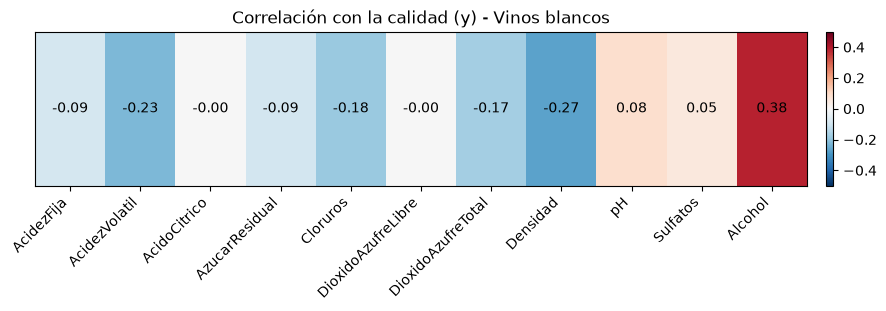

In [12]:
corr = df[df['Color'] == 0].drop(columns=['Calidad', 'Color']).corr()['y'].drop('y')

plt.figure(figsize=(12, 2))
plt.imshow([corr.values], cmap='RdBu_r', vmin=-0.5, vmax=0.5, aspect='auto')
plt.colorbar(pad=0.02)
plt.xticks(range(len(corr)), corr.index, rotation=45, ha='right')
plt.yticks([])
for j, v in enumerate(corr.values):
    plt.text(j, 0, f'{v:.2f}', ha='center', va='center')
plt.title('Correlacion con la calidad (y) - Vinos blancos')
plt.show()

***b) En los mapas de calor de la salida se ve claramente cuales son las caracteristicas mas influyentes sobre la calidad.***

***En los vinos tintos, la mas influyente es el alcohol (rojo, r ≈ 0,43: a mas alcohol, mayor probabilidad de buena calidad), seguida por la acidez volatil (azul, r ≈ -0,32), el dioxido de azufre total (r ≈ -0,23) y los sulfatos (r ≈ 0,22).***

***En los vinos blancos, la mas influyente tambien es el alcohol (r ≈ 0,38), seguida por la densidad (azul, r ≈ -0,27), la acidez volatil (r ≈ -0,23) y los cloruros (r ≈ -0,18).***

***En ambos tipos, a mas acidez volatil, menor probabilidad de buena calidad. El resto de las caracteristicas tienen una correlacion cercana a 0 con la salida y, por lo tanto, son poco relevantes por si solas.***

Lo proximo a hacer es analizar valores atipicos de nuestra red, columna por columna, para ver si hay errores, o datos que no muevan el promedio mas de lo que deberian.
Tambien esto nos servira para ver si hace falta normalizar algun dato.

In [13]:
caracteristicas = list(df.columns[:11])

filas = []
for col in caracteristicas:
    datos = df[col]
    Q1 = np.percentile(datos, 25)
    Q3 = np.percentile(datos, 75)
    RIC = Q3 - Q1                   

    lim_inf = Q1 - 1.5 * RIC
    lim_sup = Q3 + 1.5 * RIC
    es_atipico = (datos < lim_inf) | (datos > lim_sup)

    lim_inf_ext = Q1 - 3 * RIC
    lim_sup_ext = Q3 + 3 * RIC
    es_extremo = (datos < lim_inf_ext) | (datos > lim_sup_ext)

    filas.append({
        'Columna': col,
        'Q1': round(Q1, 4),
        'Q3': round(Q3, 4),
        'RIC': round(RIC, 4),
        'Limite inf.': round(lim_inf, 4),
        'Limite sup.': round(lim_sup, 4),
        'Atipicos': es_atipico.sum(),
        '% del total': round(es_atipico.mean() * 100, 1),
        'En tintos': (es_atipico & (df['Color'] == 1)).sum(),
        'En blancos': (es_atipico & (df['Color'] == 0)).sum(),
    })

tabla_atipicos = pd.DataFrame(filas)
tabla_atipicos

,Columna,Q1,Q3,RIC,Limite inf.,Limite sup.,Atipicos,% del total,En tintos,En blancos
0,AcidezFija,6.4000,7.700,1.3000,4.4500,9.6500,357,5.5,326,31
1,AcidezVolatil,0.2300,0.400,0.1700,-0.0250,0.6550,377,5.8,341,36
2,AcidoCitrico,0.2500,0.390,0.1400,0.0400,0.6000,509,7.8,323,186
3,AzucarResidual,1.8000,8.100,6.3000,-7.6500,17.5500,118,1.8,0,118
4,Cloruros,0.0380,0.065,0.0270,-0.0025,0.1055,286,4.4,179,107
5,DioxidoAzufreLibre,17.0000,41.000,24.0000,-19.0000,77.0000,62,1.0,0,62
6,DioxidoAzufreTotal,77.0000,156.000,79.0000,-41.5000,274.5000,10,0.2,2,8
7,Densidad,0.9923,0.997,0.0047,0.9854,1.0040,3,0.0,0,3
8,pH,3.1100,3.320,0.2100,2.7950,3.6350,73,1.1,34,39
9,Sulfatos,0.4300,0.600,0.1700,0.1750,0.8550,191,2.9,150,41


***D) Los datos atipicos se identificaron con la regla del rango intercuartilico (valores por debajo de Q1 - 1,5·RIC o por encima de Q3 + 1,5·RIC). Hay atipicos en casi todas las columnas. No los elimine, porque son mediciones reales, muchos son valores normales dentro de un tipo de vino (tinto o blanco) y algunos se relacionan con la calidad, por lo que eliminarlos significaria perder informacion util para la red.***

Cada fila es una caracteristica fisicoquimica y cada columna responde una pregunta distinta sobre ella:

- **Q1, Q3 y RIC:** Q1 es el valor que deja por debajo al 25% de los vinos y Q3 al 75%. El RIC (rango intercuartilico) es Q3 - Q1 y mide cuanto se dispersa el 50% central de los datos.
- **Limite inf. y Limite sup.:** son los limites de la regla del RIC (Q1 - 1,5·RIC y Q3 + 1,5·RIC). Un valor fuera de ese rango se considera atipico.
- **Atipicos y % del total:** cuantos vinos quedan fuera de los limites y que porcentaje de los 6.497 vinos representan. Indican cuantas filas se perderian si se eliminaran.
- **En tintos y En blancos:** cuantos de esos atipicos son vinos tintos y cuantos blancos. Permite ver si un valor es atipico solo al mezclar los dos tipos de vino.


**Que muestra la tabla**

- Hay atipicos en casi todas las columnas, pero en distinta cantidad: la mayor es **AcidoCitrico** (509 vinos, 7,8%), seguida por **AcidezVolatil** (377, 5,8%), **AcidezFija** (357, 5,5%) y **Cloruros** (286, 4,4%). Alcohol y Densidad tienen apenas 3 cada una.
- La mayoria son atipicos solo respecto del conjunto mezclado: por ejemplo, casi todos los de **AcidezFija** y **AcidezVolatil** son vinos tintos, y todos los de **AzucarResidual** son blancos. Son valores normales dentro de su tipo de vino.

Ahora lo que haremos es normalizar los datos para poder pasar a hacer nuestra red neuronal.

In [17]:
fisicoquimicas = list(df.columns[:11])

df_limpio = df.copy()

# Z-score solo en las 11 fisicoquimicas
df_limpio[fisicoquimicas] = (df[fisicoquimicas] - df[fisicoquimicas].mean()) / df[fisicoquimicas].std(ddof=0)

df_limpio['Calidad'] = df['y']
df_limpio = df_limpio.drop(columns='y')

df_limpio.to_csv('vinos_limpio.csv', index=False)

display(df_limpio.head())
display(df_limpio.describe().T.round(3))

,AcidezFija,AcidezVolatil,AcidoCitrico,AzucarResidual,Cloruros,DioxidoAzufreLibre,DioxidoAzufreTotal,Densidad,pH,Sulfatos,Alcohol,Calidad,Color
0,-0.783214,-0.423183,0.009406,0.180090,-0.229336,0.928250,0.765344,-0.625870,-0.052874,0.461924,0.426120,1,0
1,0.142473,1.793993,-1.504633,-0.639680,0.684143,-0.818431,-1.464058,0.888250,2.248481,1.066785,0.258422,1,1
2,-0.706073,-0.666161,0.078226,0.306208,-0.115152,-0.424019,0.039904,-0.299033,0.071523,-0.478971,-0.076974,1,0
3,-0.783214,1.763621,-0.059414,-0.786818,0.912512,-0.874776,-0.915554,0.734837,1.502096,1.738854,-0.999313,0,1
4,0.296754,-0.423183,1.385805,-0.471522,-0.372068,-0.142297,0.641489,-1.136135,-1.234651,-0.008524,0.761516,1,0


,count,mean,std,min,25%,50%,75%,max
AcidezFija,6497.0,-0.000,1.000,-2.635,-0.629,-0.166,0.374,6.699
AcidezVolatil,6497.0,0.000,1.000,-1.577,-0.666,-0.302,0.366,7.534
AcidoCitrico,6497.0,0.000,1.000,-2.193,-0.472,-0.059,0.491,9.231
AzucarResidual,6497.0,0.000,1.000,-1.018,-0.766,-0.514,0.558,12.687
Cloruros,6497.0,0.000,1.000,-1.343,-0.515,-0.258,0.256,15.842
DioxidoAzufreLibre,6497.0,0.000,1.000,-1.664,-0.762,-0.086,0.590,14.564
DioxidoAzufreTotal,6497.0,0.000,1.000,-1.942,-0.686,0.040,0.712,5.737
Densidad,6497.0,0.000,1.000,-2.530,-0.786,0.064,0.765,14.769
pH,6497.0,0.000,1.000,-3.101,-0.675,-0.053,0.631,4.923
Sulfatos,6497.0,0.000,1.000,-2.092,-0.681,-0.143,0.462,9.871


***e) Se normalizaron las 11 columnas fisicoquimicas, porque estan en escalas muy distintas: por ejemplo, el dioxido de azufre total llega hasta 440, mientras que los cloruros rondan 0,05. Sin normalizar, las columnas con valores grandes dominarian el entrenamiento de la red y las de valores chicos casi no influirian. Color y Calidad no se normalizaron porque ya estan codificadas como 0 y 1.***

***El metodo elegido fue la estandarizacion (z-score): a cada valor se le resta la media de su columna y se lo divide por el desvio estandar de esa columna.***

***Despues de normalizar, la media de cada columna da 0 y el desvio estandar da 1. La media da 0 porque al restarle a cada valor el promedio de su columna, los vinos que estaban por debajo del promedio quedan con valores negativos y los que estaban por encima quedan con valores positivos, y se compensan entre si. El desvio estandar da 1 porque despues se divide todo por el desvio original de la columna, asi que la dispersion queda medida en unidades de desvio. Un valor normalizado indica cuantos desvios se aleja ese vino del promedio de su columna: 0 es un vino justo en el promedio, un valor positivo esta por encima y uno negativo por debajo. Si en alguna columna la media aparece como -0.0, es un numero tan chico que se redondea a 0.***

***Que la media sea 0 y el desvio sea 1 en las 11 columnas confirma que la normalizacion funciono. Color y Calidad no tienen media 0 ni desvio 1 justamente porque no se normalizaron. Los valores minimos y maximos de algunas columnas se alejan bastante de 0, porque se conservaron los valores atipicos.***